# ACME Talent Insights

Answers to the seven business questions from the **Gold layer** of the ACME talent data lake.

| | Question | Gold table |
|---|---|---|
| Q1 | What are the performance ratings and review history for each employee? | `review_history`, `employee_performance_summary` |
| Q2 | Which employees have critical skill gaps in key competencies? | `skill_gaps` |
| Q3 | Who are the high-potential employees ready for promotion? | `promotion_pipeline` |
| Q4 | What training and development has each employee completed? | `training_summary` |
| Q5 | Which employees are at risk of attrition based on performance trends? | `attrition_risk` |
| Q6 | How does performance correlate with team and project outcomes? | `team_performance_outcomes` |
| Q7 | What is the distribution of skills across the organization? | `skill_distribution` |

**How to run.** Run `python job.py` first so Gold exists, then *Run All*. The notebook reads the same lake the
pipeline writes (LocalStack S3 locally, Amazon S3 in the cloud) through `storage.Lake`, configured by the same
environment variables (`PARTICIPANT_ID` or `LAKE_BUCKET`, `IS_LOCAL`). Every number below is computed from the
data at run time; nothing is typed in by hand.

In [1]:
import os
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap

JOB_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(JOB_DIR))
from config import load_settings  # noqa: E402  (pipeline config: same lake, same env vars)
from storage import Lake          # noqa: E402

settings = load_settings()
lake = Lake(settings)

GOLD_TABLES = ["review_history", "employee_performance_summary", "skill_gaps", "promotion_pipeline",
               "training_summary", "attrition_risk", "team_performance_outcomes", "skill_distribution"]
gold = {name: lake.read_parquet(f"{settings.gold_prefix}{name}/") for name in GOLD_TABLES}
catalog = lake.get_json(f"{settings.gold_prefix}_catalog.json")
RULES = catalog["rules"]

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
display(Markdown(f"Loaded **{len(gold)} Gold tables** from `{lake.uri(settings.gold_prefix)}` · "
                 f"as of **{catalog['as_of']}** · run `{catalog['run_id']}`"))

Loaded **8 Gold tables** from `s3://coding-workshop-datalake-6406ff0d/gold/` · as of **2026-10-15** · run `20261015T063415Z-54583f`

In [2]:
# Chart style: one quiet look for every figure. Colors come from a colorblind-validated palette:
# single-series charts use one blue; status colors are used only for risk tiers and always carry a text label.
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
STATUS = {"High": "#d03b3b", "Medium": "#ec835a", "Low": "#0ca30c"}
SEQ = LinearSegmentedColormap.from_list("blue_seq", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
ORDINAL = ["#0d366b", "#256abf", "#5598e7", "#9ec5f4"]  # tier 1 (darkest) -> tier 4

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 12, "text.color": INK, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})


def hbar(ax, labels, values, color=BLUE, fmt="{:,.0f}", title=None, xlabel=None):
    """Horizontal bars, largest at top, with the value printed at each bar end."""
    y = np.arange(len(labels))[::-1]
    colors = color if isinstance(color, (list, tuple)) else [color] * len(labels)
    ax.barh(y, values, height=0.62, color=colors, edgecolor=SURFACE, linewidth=2)
    ax.set_yticks(y, labels)
    ax.grid(axis="y", visible=False)
    pad = max(values) * 0.01 if len(values) else 0
    for yi, v in zip(y, values):
        ax.text(v + pad, yi, fmt.format(v), va="center", fontsize=9, color=INK)
    ax.set_xlim(0, max(values) * 1.15 if len(values) else 1)
    if title:
        ax.set_title(title)
    if xlabel:
        ax.set_xlabel(xlabel)
    return ax


def finding(text):
    """A computed, plain-language finding."""
    display(Markdown(f"> **Finding.** {text}"))

## Can we trust these numbers?

Before the answers: what the last pipeline run did, from its lineage manifest and data-quality report.
Every learning event that arrived is accounted for, either in Silver (and therefore in Gold) or in quarantine
with a reason.

In [3]:
manifest = lake.get_json(f"{settings.lineage_prefix}latest.json")
health = pd.DataFrame([
    {"layer": s["layer"], "dataset": s["dataset"], "rows read": s["rows_read"], "rows written": s["rows_written"],
     "quarantined": s["rows_quarantined"], "status": s["status"]}
    for s in manifest["steps"] if s["dataset"] != "_summary"
])
display(Markdown(f"Last run `{manifest['run_id']}` **{manifest['status']}** in {manifest['duration_s']} s "
                 f"(layers: {', '.join(manifest['totals'])})."))
display(health)

dq_key = f"{settings.quarantine_prefix}_reports/run_date={catalog['as_of']}/dq_report.json"
dq = lake.get_json(dq_key, default=None)
if dq:
    la = dq["datasets"]["learning_activity"]
    reasons = pd.Series(la["quarantine_reasons"]).sort_values(ascending=False)
    finding(f"{la['rows_in']:,} learning-event lines arrived; {la['rows_valid']:,} are valid "
            f"and {la['rows_quarantined']:,} ({la['rows_quarantined'] / la['rows_in']:.1%}) were quarantined: "
            + ", ".join(f"{k.replace('_', ' ')} {v}" for k, v in reasons.items())
            + ". The HR tables had no rejected rows.")

Last run `20261015T063415Z-54583f` **succeeded** in 1.806 s (layers: gold).

,layer,dataset,rows read,rows written,quarantined,status
0,gold,review_history,41747,4000,0,succeeded
1,gold,employee_performance_summary,41747,2000,0,succeeded
2,gold,skill_gaps,41747,993,0,succeeded
3,gold,promotion_pipeline,41747,2000,0,succeeded
4,gold,training_summary,41747,2000,0,succeeded
5,gold,attrition_risk,41747,2000,0,succeeded
6,gold,team_performance_outcomes,41747,100,0,succeeded
7,gold,skill_distribution,41747,440,0,succeeded


> **Finding.** 29,868 learning-event lines arrived; 29,574 are valid and 294 (1.0%) were quarantined: duplicate pk 151, missing 91, invalid datetime 39, malformed json 13. The HR tables had no rejected rows.

## Q1 · Performance ratings and review history

Each employee has two half-year reviews (2024-H2 and 2025-H1) rated 1–5. The summary table keeps the latest
rating, the change from the previous review, and the full history as text.

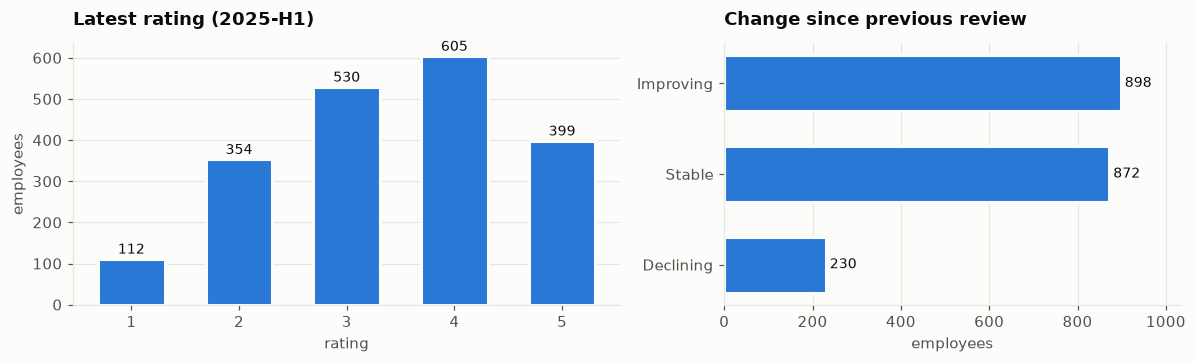

> **Finding.** Average latest rating is **3.41**. 898 employees improved and **230 declined**; 84 of them dropped by two points or more.

In [4]:
perf = gold["employee_performance_summary"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1.2, 1]})
dist = perf["latest_rating"].value_counts().reindex(range(1, 6), fill_value=0)
a1.bar(dist.index, dist.values, width=0.62, color=BLUE, edgecolor=SURFACE, linewidth=2)
for x, v in zip(dist.index, dist.values):
    a1.text(x, v + dist.max() * 0.02, f"{v:,}", ha="center", fontsize=9)
a1.set_title("Latest rating (2025-H1)")
a1.set_xlabel("rating")
a1.set_ylabel("employees")
a1.set_xticks(range(1, 6))
a1.grid(axis="x", visible=False)
trend = perf["rating_trend"].value_counts().reindex(["Improving", "Stable", "Declining"])
hbar(a2, trend.index, trend.values, title="Change since previous review", xlabel="employees")
plt.tight_layout()
plt.show()

declining = perf[perf["rating_trend"] == "Declining"]
finding(f"Average latest rating is **{perf['latest_rating'].mean():.2f}**. "
        f"{trend['Improving']:,} employees improved and **{trend['Declining']:,} declined**; "
        f"{(declining['rating_change'] <= -2).sum()} of them dropped by two points or more.")

In [5]:
# Look up any employee's review history (change the name to explore).
def review_history(name):
    rows = gold["review_history"]
    return rows[rows["full_name"].str.contains(name, case=False)][
        ["employee_id", "full_name", "department", "review_period", "rating", "rating_change", "manager_comment"]]

display(review_history("Anne Long"))

display(Markdown("**Largest rating drops** (latest vs previous review)"))
display(perf.nsmallest(10, ["rating_change"])[
    ["employee_id", "full_name", "team_name", "department", "rating_history", "latest_comment"]])

,employee_id,full_name,department,review_period,rating,rating_change,manager_comment
740,371,Anne Long,Operations,2024-H2,4,<NA>,"Solid, consistent contributor this cycle."
741,371,Anne Long,Operations,2025-H1,2,-2,Engagement and output have both trended down.


**Largest rating drops** (latest vs previous review)

,employee_id,full_name,team_name,department,rating_history,latest_comment
69,70,Mike Gamble,Team OliveDrab-5,Operations,2024-H2:3 -> 2025-H1:1,Engagement and output have both trended down.
123,124,Lindsey Murphy,Team DarkMagenta-7,Finance,2024-H2:3 -> 2025-H1:1,Struggled to meet deadlines; follow-up plan re...
130,131,Robert Allen,Team Black-8,Product,2024-H2:4 -> 2025-H1:2,Engagement and output have both trended down.
138,139,Kenneth Jones,Team Black-8,Product,2024-H2:3 -> 2025-H1:1,Engagement and output have both trended down.
193,194,Carly Bennett,Team PaleTurquoise-11,Data & Analytics,2024-H2:3 -> 2025-H1:1,Engagement and output have both trended down.
228,229,Crystal Moore,Team Moccasin-13,Customer Support,2024-H2:3 -> 2025-H1:1,Engagement and output have both trended down.
236,237,Nicholas Gonzales,Team Moccasin-13,Customer Support,2024-H2:4 -> 2025-H1:2,Missed several key deliverables this cycle; ne...
244,245,Karen Rosales,Team Moccasin-13,Customer Support,2024-H2:4 -> 2025-H1:2,Struggled to meet deadlines; follow-up plan re...
256,257,Raymond Waters,Team BlanchedAlmond-14,Marketing,2024-H2:3 -> 2025-H1:1,Struggled to meet deadlines; follow-up plan re...
294,295,Paula Davies,Team Gold-16,Product,2024-H2:3 -> 2025-H1:1,Struggled to meet deadlines; follow-up plan re...


## Q2 · Critical skill gaps in key competencies

A **critical gap** is defined in the pipeline (see `gold/_catalog.json`):
the employee's latest assessment is two or more levels below the required level, or below it at all where the role
requires level 4 or higher.

*Rule:* latest assessment short of required level by >= 2, or short by any amount where the role requires level >= 4

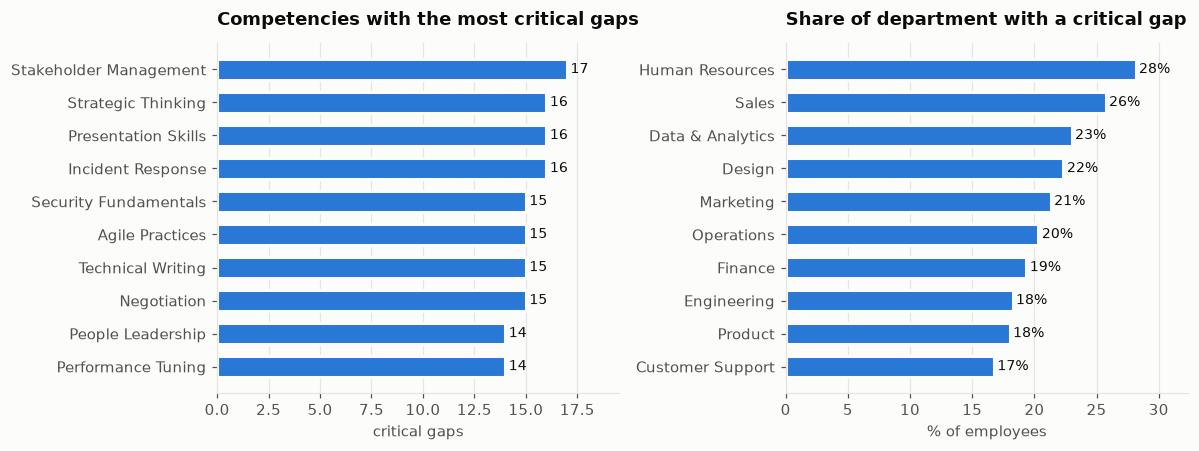

> **Finding.** **465 critical gaps** affect **441 employees** (22% of the workforce). The most common is **Stakeholder Management** (17). Human Resources has the highest share of people with a critical gap (28%).

**Largest individual gaps**

,employee_id,full_name,department,job_level,competency,proficiency_level,required_level,gap
0,2,Kristie Heath,Sales,Director,Strategic Thinking,2,4,2
4,31,Douglas Salinas,Design,Director,Data Privacy,2,4,2
7,40,Lindsey Harris,Design,IC1,People Leadership,2,4,2
9,52,Kelly Smith,Sales,Senior IC,Agile Practices,2,4,2
10,55,Christine Roberts,Sales,Senior Manager,Decision Making,2,4,2
11,56,Cody Scott,Sales,IC3,Strategic Thinking,2,4,2
17,101,Amanda Jackson,Customer Support,Senior Manager,Technical Writing,2,4,2
21,120,Ryan Baker,Finance,Director,Project Management,2,4,2
23,143,Lisa Smith,Product,IC2,Time Management,2,4,2
24,150,Sarah Young,Product,IC3,Stakeholder Management,2,4,2


In [6]:
gaps = gold["skill_gaps"]
crit = gaps[gaps["is_critical_gap"]]
display(Markdown(f"*Rule:* {RULES['critical_skill_gap']}"))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
top = crit["competency"].value_counts().head(10)
hbar(a1, top.index, top.values, title="Competencies with the most critical gaps", xlabel="critical gaps")
by_dept = (crit.groupby("department")["employee_id"].nunique()
           / gold["employee_performance_summary"].groupby("department")["employee_id"].count() * 100
           ).sort_values(ascending=False)
hbar(a2, by_dept.index, by_dept.values, fmt="{:.0f}%", title="Share of department with a critical gap",
     xlabel="% of employees")
plt.tight_layout()
plt.show()

finding(f"**{len(crit):,} critical gaps** affect **{crit['employee_id'].nunique():,} employees** "
        f"({crit['employee_id'].nunique() / len(gold['employee_performance_summary']):.0%} of the workforce). "
        f"The most common is **{top.index[0]}** ({top.iloc[0]}). "
        f"{by_dept.index[0]} has the highest share of people with a critical gap ({by_dept.iloc[0]:.0f}%).")

display(Markdown("**Largest individual gaps**"))
display(crit.sort_values(["gap", "required_level"], ascending=False).head(10)[
    ["employee_id", "full_name", "department", "job_level", "competency", "proficiency_level",
     "required_level", "gap"]])

## Q3 · High-potential employees ready for promotion

The pipeline combines the talent review (potential, readiness), the latest performance rating and open critical
skill gaps into four tiers.

- **1 - Ready now**: high potential, readiness 'Ready Now', no critical skill gaps

- **2 - Ready now, close skill gaps**: high potential, readiness 'Ready Now', >= 1 critical gap

- **3 - Emerging (1-2 years)**: high potential, readiness '1-2 Years'

- **4 - Not in pipeline**: everyone else

- *High potential* = talent review potential = High and latest rating >= 4

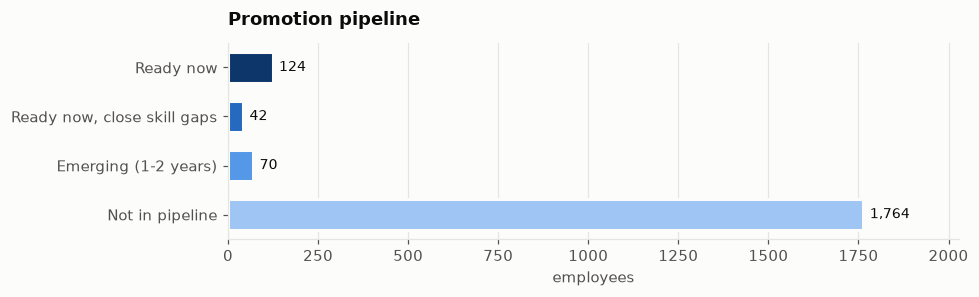

> **Finding.** **124 employees are ready for promotion now**, 42 more once they close a critical skill gap, and 70 are emerging within 1–2 years. **28 high-potential employees are also rated high attrition risk** by their manager: the most urgent retention conversations.

**Ready now** (top 15 by latest and average rating)

,employee_id,full_name,department,job_level,tenure_years,latest_rating,avg_rating,rating_trend,certifications_earned
0,84,Daniel Osborne,Customer Support,Manager,5.8,5,4.5,Improving,2
1,96,Jacob Jordan,Customer Support,Manager,3.4,5,4.5,Improving,0
2,145,Lisa Johnson,Product,Manager,2.8,5,4.5,Improving,2
3,242,Amanda Harper,Customer Support,IC1,0.6,5,4.5,Improving,0
4,248,Lindsey Gonzales,Customer Support,Senior Manager,5.4,5,4.5,Improving,1
5,272,Paul Smith,Engineering,IC3,6.4,5,4.5,Improving,1
6,359,Cameron Williams,Data & Analytics,Manager,5.2,5,4.5,Improving,0
7,391,Patrick Harris,Product,Senior Manager,4.5,5,4.5,Improving,1
8,498,Christina Herrera,Human Resources,Senior IC,5.9,5,4.5,Improving,0
9,506,Vanessa Pugh,Human Resources,Director,2.3,5,4.5,Improving,0


**High potential at high attrition risk**

,employee_id,full_name,department,job_level,promotion_tier,latest_rating,attrition_risk
0,84,Daniel Osborne,Customer Support,Manager,1 - Ready now,5,High
5,272,Paul Smith,Engineering,IC3,1 - Ready now,5,High
13,604,James Mccarthy,Human Resources,IC3,1 - Ready now,5,High
26,1750,Kevin Bryant,Finance,IC2,1 - Ready now,5,High
45,157,Dennis Scott,Engineering,IC2,1 - Ready now,4,High
69,1287,Michael Cortez,Finance,Senior IC,1 - Ready now,4,High
80,1862,Zachary Collins,Data & Analytics,IC2,1 - Ready now,4,High
84,1,Heather Davis,Sales,Director,1 - Ready now,4,High
95,760,Joseph Nash,Product,Manager,1 - Ready now,4,High
98,1043,Jennifer Carter,Human Resources,IC3,1 - Ready now,4,High


In [7]:
promo = gold["promotion_pipeline"]
for tier, rule in RULES["promotion_tiers"].items():
    display(Markdown(f"- **{tier}**: {rule}"))
display(Markdown(f"- *High potential* = {RULES['high_potential']}"))

tiers = promo["promotion_tier"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 2.8))
hbar(ax, [t.split(" - ")[1] for t in tiers.index], tiers.values, color=ORDINAL,
     title="Promotion pipeline", xlabel="employees")
plt.tight_layout()
plt.show()

ready = promo[promo["promotion_tier"] == "1 - Ready now"]
flagged = promo[promo["retention_flag"]]
finding(f"**{len(ready)} employees are ready for promotion now**, {tiers.iloc[1]} more once they close a critical "
        f"skill gap, and {tiers.iloc[2]} are emerging within 1–2 years. "
        f"**{len(flagged)} high-potential employees are also rated high attrition risk** by their manager: "
        f"the most urgent retention conversations.")

display(Markdown("**Ready now** (top 15 by latest and average rating)"))
display(ready.head(15)[["employee_id", "full_name", "department", "job_level", "tenure_years", "latest_rating",
                        "avg_rating", "rating_trend", "certifications_earned"]])
display(Markdown("**High potential at high attrition risk**"))
display(flagged[["employee_id", "full_name", "department", "job_level", "promotion_tier", "latest_rating",
                 "attrition_risk"]].head(15))

## Q4 · Training and development completed

Learning events (enrolments, modules, quizzes, course completions, certifications) rolled up per employee.
Employees with no activity at all are kept with zeros, so they are visible rather than missing.

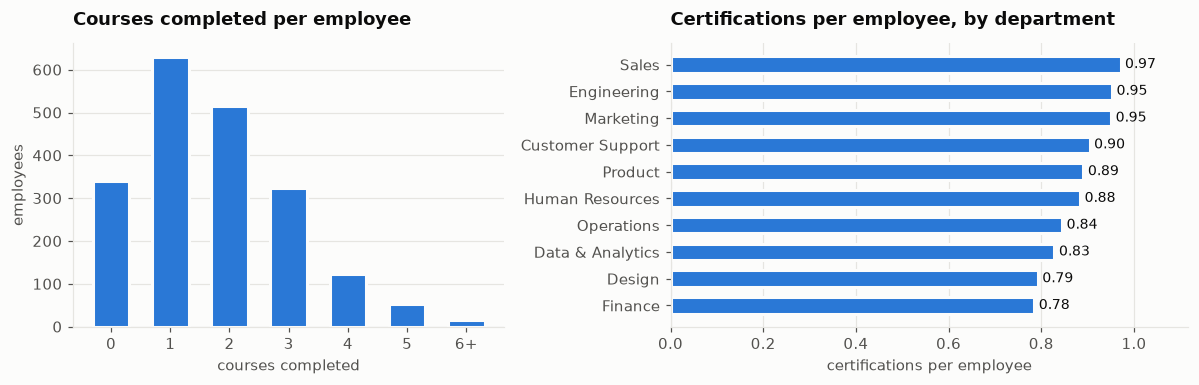

> **Finding.** Employees completed **1.75 courses** on average and earned **1,764 certifications**. **232 employees have no recorded learning activity**, and 183 have none in the last 180 days. Quiz pass rate across the organisation is 41%.

,employee_id,full_name,enrollments,courses_completed,certifications_earned,quiz_pass_rate,last_activity,courses_completed_list,certifications_list
370,371,Anne Long,0,3,0,0.0,2025-10-06 19:41:00,Incident Response Drills; Localization Best Pr...,<NA>


In [8]:
train = gold["training_summary"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.2]})
courses = train["courses_completed"].clip(upper=6).value_counts().sort_index()
a1.bar(courses.index, courses.values, width=0.62, color=BLUE, edgecolor=SURFACE, linewidth=2)
a1.set_xticks(courses.index, [str(i) if i < 6 else "6+" for i in courses.index])
a1.set_title("Courses completed per employee")
a1.set_xlabel("courses completed")
a1.set_ylabel("employees")
a1.grid(axis="x", visible=False)
certs = train.groupby("department")["certifications_earned"].mean().sort_values(ascending=False)
hbar(a2, certs.index, certs.values, fmt="{:.2f}", title="Certifications per employee, by department",
     xlabel="certifications per employee")
plt.tight_layout()
plt.show()

none = train[train["enrollments"] == 0]
inactive = train[~train["learning_active"].astype(bool)]
finding(f"Employees completed **{train['courses_completed'].mean():.2f} courses** on average and earned "
        f"**{int(train['certifications_earned'].sum()):,} certifications**. "
        f"**{len(none)} employees have no recorded learning activity**, and {len(inactive)} have none in the last "
        f"{re.search(r'(\d+) days', RULES['learning_active']).group(1)} days. Quiz pass rate across the organisation is "
        f"{train['quizzes_passed'].sum() / (train['quizzes_passed'] + train['quizzes_failed']).sum():.0%}.")

def training_record(name):
    rows = train[train["full_name"].str.contains(name, case=False)]
    return rows[["employee_id", "full_name", "enrollments", "courses_completed", "certifications_earned",
                 "quiz_pass_rate", "last_activity", "courses_completed_list", "certifications_list"]]

display(training_record("Anne Long"))

## Q5 · Attrition risk from performance trends

A transparent, rule-based score (no black box): each signal adds points, and every employee's row lists the
signals that fired. The manager's own attrition flag from the talent review is one signal, not the whole answer.

,points
signal,
rating_declined,2
low_latest_rating,2
negative_manager_comment,1
no_recent_learning,1
manager_flag_high,2
manager_flag_medium,1


Tiers: **High** score >= 5, **Medium** score >= 3, **Low** score >= 0

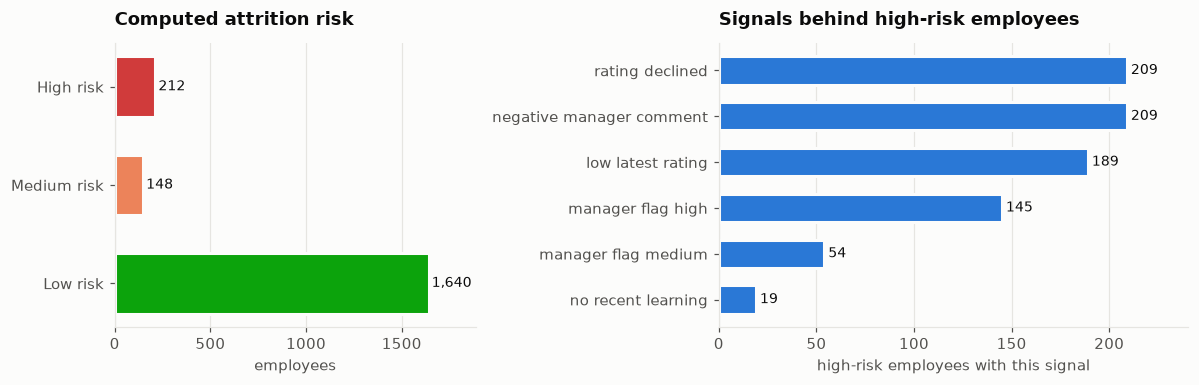

**Manager flag (rows) vs computed tier (columns)**

computed_risk_tier,High,Medium,Low
manager_attrition_risk,,,
High,145,37,129
Medium,54,92,466
Low,13,19,1045


> **Finding.** **212 employees are high risk** and 148 medium. Managers flagged 311 people as high risk; only **145** of them also show performance warning signs, while **129** look stable on performance and learning. Conversely 67 employees score high risk although their manager did not flag them as high.

**Highest risk employees**

,employee_id,full_name,department,rating_history,latest_comment,manager_attrition_risk,risk_score,risk_drivers
0,111,Brian Brock,Finance,2024-H2:2 -> 2025-H1:1,Engagement and output have both trended down.,High,8,"rating_declined, low_latest_rating, negative_m..."
1,243,Robert Brady,Customer Support,2024-H2:3 -> 2025-H1:2,Struggled to meet deadlines; follow-up plan re...,High,8,"rating_declined, low_latest_rating, negative_m..."
2,371,Anne Long,Operations,2024-H2:4 -> 2025-H1:2,Engagement and output have both trended down.,High,8,"rating_declined, low_latest_rating, negative_m..."
3,702,Crystal Logan,Marketing,2024-H2:3 -> 2025-H1:1,Struggled to meet deadlines; follow-up plan re...,High,8,"rating_declined, low_latest_rating, negative_m..."
4,1147,David Mcclure,Human Resources,2024-H2:2 -> 2025-H1:1,Engagement and output have both trended down.,High,8,"rating_declined, low_latest_rating, negative_m..."
5,1225,Amy Tucker,Marketing,2024-H2:2 -> 2025-H1:1,Engagement and output have both trended down.,High,8,"rating_declined, low_latest_rating, negative_m..."
6,1299,Joseph Ford,Design,2024-H2:2 -> 2025-H1:1,Struggled to meet deadlines; follow-up plan re...,High,8,"rating_declined, low_latest_rating, negative_m..."
7,1550,Rodney Wilkerson,Customer Support,2024-H2:3 -> 2025-H1:2,Missed several key deliverables this cycle; ne...,High,8,"rating_declined, low_latest_rating, negative_m..."
8,8,Sherry Coleman,Sales,2024-H2:3 -> 2025-H1:2,Missed several key deliverables this cycle; ne...,High,7,"rating_declined, low_latest_rating, negative_m..."
9,45,Donna Green,Sales,2024-H2:3 -> 2025-H1:2,Missed several key deliverables this cycle; ne...,High,7,"rating_declined, low_latest_rating, negative_m..."


In [9]:
risk = gold["attrition_risk"]
display(pd.DataFrame({"points": RULES["attrition_points"]}).rename_axis("signal"))
display(Markdown(f"Tiers: {', '.join(f'**{k}** {v}' for k, v in RULES['attrition_tiers'].items())}"))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.3]})
tiers = risk["computed_risk_tier"].value_counts().reindex(["High", "Medium", "Low"])
hbar(a1, [f"{t} risk" for t in tiers.index], tiers.values, color=[STATUS[t] for t in tiers.index],
     title="Computed attrition risk", xlabel="employees")
drivers = (risk.loc[risk["computed_risk_tier"] == "High", "risk_drivers"].str.split(", ").explode()
           .value_counts())
hbar(a2, [d.replace("_", " ") for d in drivers.index], drivers.values,
     title="Signals behind high-risk employees", xlabel="high-risk employees with this signal")
plt.tight_layout()
plt.show()

agree = pd.crosstab(risk["manager_attrition_risk"], risk["computed_risk_tier"]).reindex(
    index=["High", "Medium", "Low"], columns=["High", "Medium", "Low"], fill_value=0)
display(Markdown("**Manager flag (rows) vs computed tier (columns)**"))
display(agree)

mh = agree.loc["High"]
finding(f"**{tiers['High']} employees are high risk** and {tiers['Medium']} medium. "
        f"Managers flagged {mh.sum()} people as high risk; only **{mh['High']}** of them also show performance "
        f"warning signs, while **{mh['Low']}** look stable on performance and learning. "
        f"Conversely {agree.loc['Low', 'High'] + agree.loc['Medium', 'High']} employees score high risk "
        f"although their manager did not flag them as high.")

display(Markdown("**Highest risk employees**"))
display(risk.head(15)[["employee_id", "full_name", "department", "rating_history", "latest_comment",
                       "manager_attrition_risk", "risk_score", "risk_drivers"]])

## Q6 · Performance versus team and project outcomes

Projects belong to teams, not individuals, so this is answered at team level: each team's people metrics against
the delivery outcomes of its projects. Only the 27 teams that own a project can be compared, so treat the
correlations as indicative, not proof.

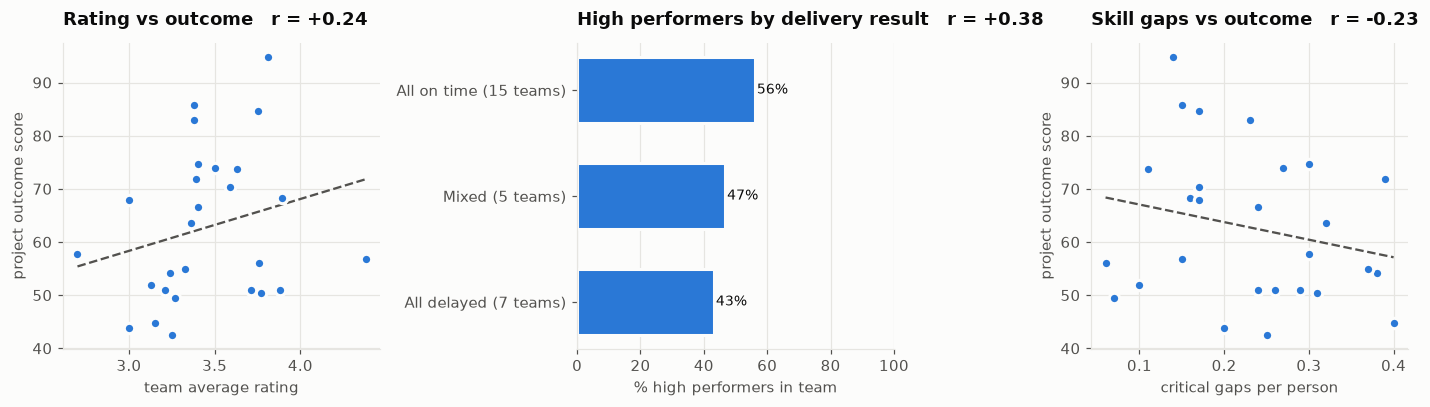

> **Finding.** Across 27 teams with projects, better-rated teams tend to deliver better outcomes (r = +0.24), teams with more high performers deliver on time more often (r = +0.38), and teams with more critical skill gaps score lower (r = -0.23). Teams whose projects were all on time have 56% high performers versus 43% for teams with delayed projects. Teams whose projects were all on time average a rating of 3.60 versus 3.27 for teams with a delayed project. The relationships are moderate and the sample is small.

,team_name,department,headcount,avg_latest_rating,pct_high_performers,critical_gaps_per_head,projects,avg_outcome_score,pct_projects_on_time
88,Team YellowGreen-89,Human Resources,21,3.81,61.90,0.14,OrangeRed Rollout,94.76,100.0
12,Team Moccasin-13,Customer Support,26,3.38,53.85,0.15,SaddleBrown Migration,85.79,100.0
33,Team GreenYellow-34,Operations,12,3.75,66.67,0.17,OliveDrab Rollout,84.68,100.0
86,Team BlanchedAlmond-87,Operations,13,3.38,46.15,0.23,PowderBlue Revamp,82.88,100.0
5,Team SlateBlue-6,Customer Support,20,3.40,50.00,0.30,DarkOliveGreen Migration,74.61,100.0
42,Team BurlyWood-43,Data & Analytics,22,3.50,50.00,0.27,Red Revamp,73.89,100.0
8,Team HoneyDew-9,Engineering,19,3.63,52.63,0.11,SeaGreen Revamp,73.67,100.0
14,Team Cornsilk-15,Engineering,18,3.39,44.44,0.39,LightSeaGreen Migration,71.90,100.0
7,Team Black-8,Product,29,3.59,51.72,0.17,SpringGreen Revamp,70.33,100.0
37,Team Olive-38,Data & Analytics,19,3.89,63.16,0.16,LightGreen Rollout; Pink Migration,68.32,50.0


In [10]:
teams = gold["team_performance_outcomes"]
wp = teams[teams["has_projects"]].copy()

def scatter(ax, x, y, xlabel, ylabel, title):
    ax.scatter(wp[x], wp[y], s=46, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
    slope, intercept = np.polyfit(wp[x].astype(float), wp[y].astype(float), 1)
    xs = np.linspace(wp[x].min(), wp[x].max(), 50)
    ax.plot(xs, slope * xs + intercept, color=INK2, linewidth=1.5, linestyle="--", zorder=2)
    r = wp[x].astype(float).corr(wp[y].astype(float))
    ax.set_title(f"{title}   r = {r:+.2f}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    return r

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
r1 = scatter(axes[0], "avg_latest_rating", "avg_outcome_score", "team average rating", "project outcome score",
             "Rating vs outcome")
# Teams own only 1-2 projects, so "% on time" is 0, 50 or 100: compare groups instead of plotting a fake slope.
r2 = wp["pct_high_performers"].astype(float).corr(wp["pct_projects_on_time"].astype(float))
wp["delivery"] = np.select([wp["pct_projects_on_time"] == 100, wp["pct_projects_on_time"] == 0],
                           ["All on time", "All delayed"], default="Mixed")
grp = wp.groupby("delivery")["pct_high_performers"].agg(["mean", "count"]).reindex(
    ["All on time", "Mixed", "All delayed"]).dropna()
hbar(axes[1], [f"{d} ({int(n)} teams)" for d, n in zip(grp.index, grp["count"])], grp["mean"].values,
     fmt="{:.0f}%", title=f"High performers by delivery result   r = {r2:+.2f}", xlabel="% high performers in team")
axes[1].set_xlim(0, 100)
r3 = scatter(axes[2], "critical_gaps_per_head", "avg_outcome_score", "critical gaps per person",
             "project outcome score", "Skill gaps vs outcome")
plt.tight_layout()
plt.show()

on_time = wp[wp["pct_projects_on_time"] == 100]
delayed = wp[wp["pct_projects_on_time"] < 100]
finding(f"Across {len(wp)} teams with projects, better-rated teams tend to deliver better outcomes "
        f"(r = {r1:+.2f}), teams with more high performers deliver on time more often (r = {r2:+.2f}), and "
        f"teams with more critical skill gaps score lower (r = {r3:+.2f}). Teams whose projects were all on time have "
        f"{grp.loc['All on time', 'mean']:.0f}% high performers versus {grp['mean'].drop('All on time').min():.0f}% "
        f"for teams with delayed projects. Teams whose projects were all on time "
        f"average a rating of {on_time['avg_latest_rating'].mean():.2f} versus {delayed['avg_latest_rating'].mean():.2f} "
        f"for teams with a delayed project. The relationships are moderate and the sample is small.")

display(wp.sort_values("avg_outcome_score", ascending=False)[
    ["team_name", "department", "headcount", "avg_latest_rating", "pct_high_performers", "critical_gaps_per_head",
     "projects", "avg_outcome_score", "pct_projects_on_time"]].head(10))

## Q7 · Distribution of skills across the organization

Latest assessment per employee and competency, by department. The heatmap shows the share of assessed
employees who meet the level their role requires; lighter cells are where the organisation is short.

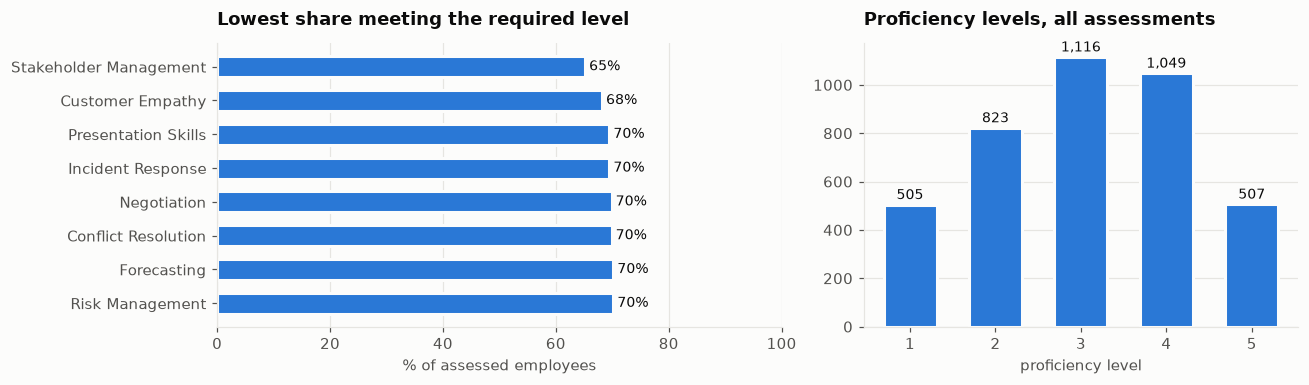

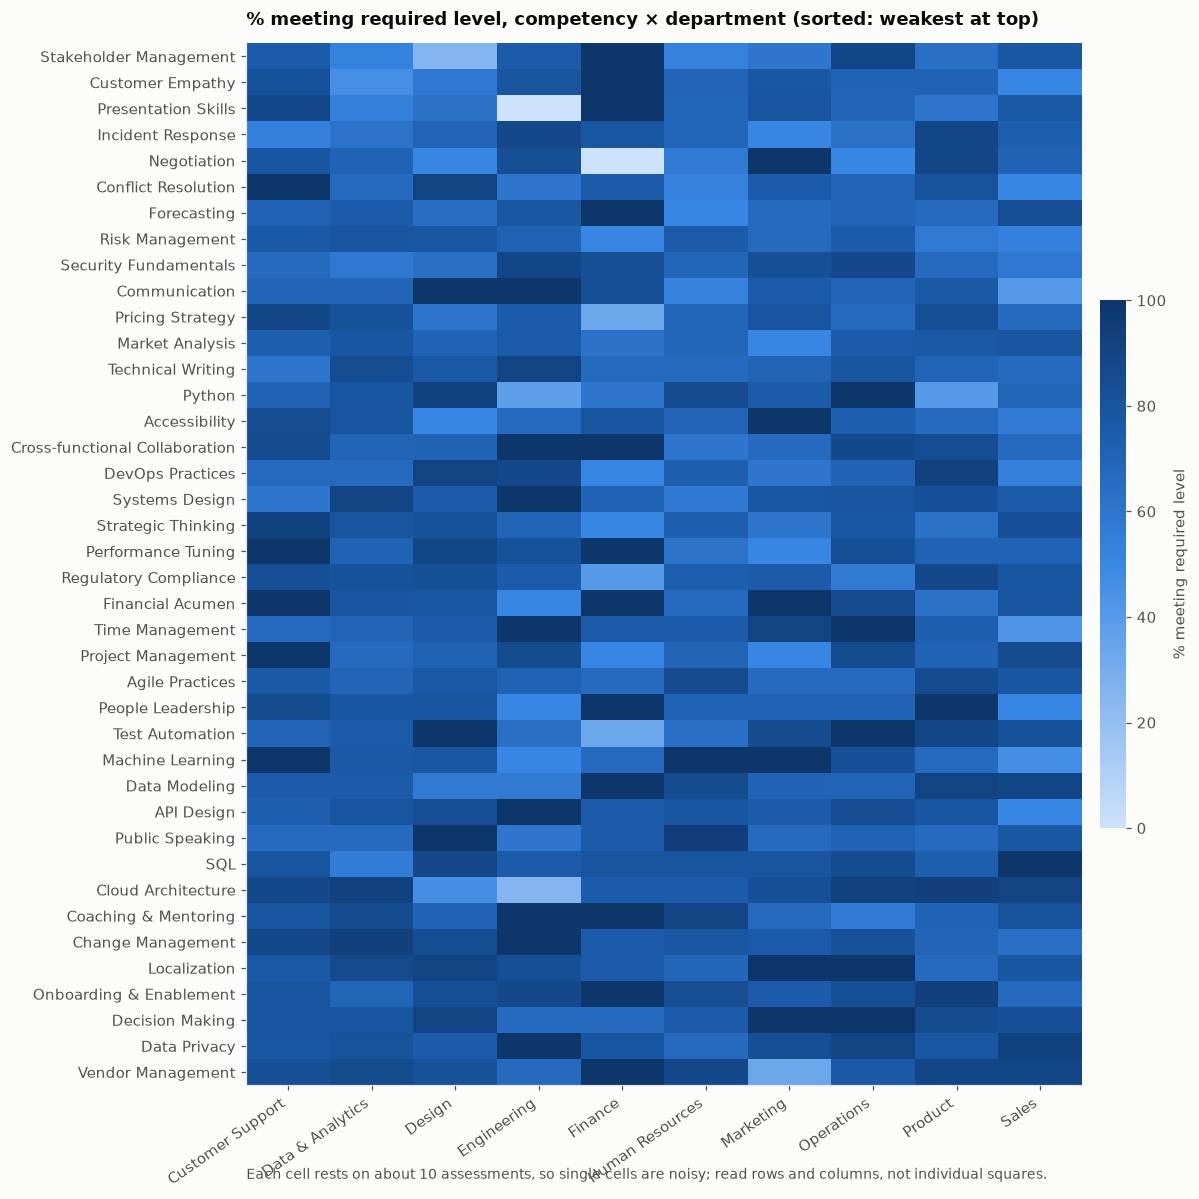

> **Finding.** Across 40 competencies, 33% of assessments sit at level 1–2 and 39% at level 4–5. Weakest coverage: **Stakeholder Management** (65% meet the required level), then Customer Empathy and Presentation Skills. Technical, leadership and domain skills average a similar proficiency (Domain 3.00, Leadership 3.10, Technical 3.10).

,avg proficiency,% meeting required
competency_category,,
Domain,3.0,74.4
Leadership,3.1,77.2
Technical,3.1,75.2


In [11]:
skills = gold["skill_distribution"]
org = skills[skills["department"] == "All"].sort_values("pct_meeting_required")
dept = skills[skills["department"] != "All"]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})
low = org.head(8)
hbar(a1, low["competency"], low["pct_meeting_required"], fmt="{:.0f}%",
     title="Lowest share meeting the required level", xlabel="% of assessed employees")
a1.set_xlim(0, 100)
levels = org[[f"level_{i}" for i in range(1, 6)]].sum()
a2.bar(range(1, 6), levels.values, width=0.62, color=BLUE, edgecolor=SURFACE, linewidth=2)
for x, v in zip(range(1, 6), levels.values):
    a2.text(x, v + levels.max() * 0.02, f"{v:,}", ha="center", fontsize=9)
a2.set_title("Proficiency levels, all assessments")
a2.set_xlabel("proficiency level")
a2.set_xticks(range(1, 6))
a2.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

grid = dept.pivot_table(index="competency", columns="department", values="pct_meeting_required")
grid = grid.loc[org["competency"]]
fig, ax = plt.subplots(figsize=(11, 11))
im = ax.imshow(grid.values, cmap=SEQ, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(grid.columns)), grid.columns, rotation=35, ha="right")
ax.set_yticks(range(len(grid.index)), grid.index)
ax.grid(False)
ax.set_title("% meeting required level, competency × department (sorted: weakest at top)")
ax.text(0, -0.09, f"Each cell rests on about {int(dept['employees_assessed'].median())} assessments, so single "
        "cells are noisy; read rows and columns, not individual squares.", transform=ax.transAxes,
        fontsize=9, color=INK2)
cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label("% meeting required level")
cbar.outline.set_visible(False)
plt.tight_layout()
plt.show()

by_cat = org.groupby("competency_category")[["avg_proficiency", "pct_meeting_required"]].mean().round(1)
finding(f"Across {org['competency'].nunique()} competencies, {levels.iloc[[0, 1]].sum() / levels.sum():.0%} of "
        f"assessments sit at level 1–2 and {levels.iloc[[3, 4]].sum() / levels.sum():.0%} at level 4–5. "
        f"Weakest coverage: **{org.iloc[0]['competency']}** ({org.iloc[0]['pct_meeting_required']:.0f}% meet the "
        f"required level), then {org.iloc[1]['competency']} and {org.iloc[2]['competency']}. "
        f"Technical, leadership and domain skills average a similar proficiency "
        f"({', '.join(f'{c} {v:.2f}' for c, v in by_cat['avg_proficiency'].items())}).")
display(by_cat.rename(columns={"avg_proficiency": "avg proficiency", "pct_meeting_required": "% meeting required"}))

## Summary for HR leadership

The headline answers the pipeline publishes with every run (`gold/_summary.json`):

In [12]:
summary = lake.get_json(f"{settings.gold_prefix}_summary.json")["answers"]
lines = []
s = summary
lines.append(f"- **Q1** {s['Q1_performance']['employees_reviewed']:,} employees reviewed, average latest rating "
             f"{s['Q1_performance']['avg_latest_rating']}; {s['Q1_performance']['rating_trend']['Declining']} declining.")
lines.append(f"- **Q2** {s['Q2_skill_gaps']['critical_gaps']} critical skill gaps across "
             f"{s['Q2_skill_gaps']['employees_with_critical_gap']} employees.")
lines.append(f"- **Q3** {s['Q3_promotion']['tiers']['1 - Ready now']} ready for promotion now; "
             f"{s['Q3_promotion']['high_potential_at_high_attrition_risk']} high-potential employees at high attrition risk.")
lines.append(f"- **Q4** {s['Q4_training']['avg_courses_completed']} courses completed per employee; "
             f"{s['Q4_training']['employees_with_no_learning_activity']} with no learning activity.")
lines.append(f"- **Q5** {s['Q5_attrition']['computed_tiers'].get('High', 0)} high attrition risk; managers' high flag "
             f"confirmed by performance signals for {s['Q5_attrition']['manager_high_also_computed_high']} of "
             f"{s['Q5_attrition']['manager_high_total']}.")
lines.append(f"- **Q6** Team rating vs project outcome r = {s['Q6_team_outcomes']['corr_avg_rating_vs_outcome_score']:+.2f}; "
             f"high performers vs on-time r = {s['Q6_team_outcomes']['corr_pct_high_performers_vs_on_time']:+.2f} "
             f"({s['Q6_team_outcomes']['teams_with_projects']} teams).")
weakest = next(iter(s['Q7_skill_distribution']['lowest_pct_meeting_required'].items()))
lines.append(f"- **Q7** Weakest competency coverage: {weakest[0]} ({weakest[1]:.0f}% meet the required level).")
display(Markdown("\n".join(lines)))

- **Q1** 2,000 employees reviewed, average latest rating 3.41; 230 declining.
- **Q2** 465 critical skill gaps across 441 employees.
- **Q3** 124 ready for promotion now; 28 high-potential employees at high attrition risk.
- **Q4** 1.75 courses completed per employee; 232 with no learning activity.
- **Q5** 212 high attrition risk; managers' high flag confirmed by performance signals for 145 of 311.
- **Q6** Team rating vs project outcome r = +0.24; high performers vs on-time r = +0.38 (27 teams).
- **Q7** Weakest competency coverage: Stakeholder Management (65% meet the required level).

### Limitations

- Two review periods per employee give one trend step; a longer history would allow a slope instead of a single change.
- Projects link to teams only, and 27 of 100 teams have any, so Q6 correlations rest on 27 points.
- The talent-review potential rating barely tracks performance in this data, so promotion and attrition answers
  deliberately combine it with ratings, skills and learning rather than trusting it alone.
- 294 learning-event lines (1.0%) are quarantined. 151 are duplicates whose original is counted, so the real loss
  is 143 events (about 0.5%: missing employee, unreadable date or broken line). They are not counted in Q4 until
  the source system corrects them.